# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:blue">  Tommaso Cardano Chiezzi</span>


# Esercizio 10.1 — Parallel Genetic Algorithm con MPI

## Obiettivo e implementazione

L'obiettivo dell'esercizio è parallelizzare, mediante **MPI (Message Passing Interface)**, l'algoritmo genetico sviluppato nell'Esercizio 9 per risolvere il **Travelling Salesman Problem (TSP)**.

Il problema consiste nel determinare il percorso chiuso di lunghezza minima che visita tutte le $N$ città esattamente una volta, minimizzando la funzione costo:

$$
L^{(1)}(\mathbf{x}) =
\sum_{i=1}^{N}
\left|\mathbf{r}_{x_i}-\mathbf{r}_{x_{i+1}}\right|,
\qquad x_{N+1}=x_1
$$

La parallelizzazione è realizzata attraverso l'**Island Model**, nel quale ogni processo MPI rappresenta un continente e gestisce una popolazione genetica indipendente.

Viene adottato il paradigma **SPMD (Single Program Multiple Data)**: tutti i processi eseguono lo stesso programma C++, ma utilizzano popolazioni e sequenze pseudocasuali differenti.

L'ambiente parallelo viene inizializzato mediante `MPI_Init()`. Tutti i processi appartengono inizialmente al comunicatore `MPI_COMM_WORLD` e sono identificati attraverso:

- `MPI_Comm_size()`: restituisce il numero totale di processi $p$.
- `MPI_Comm_rank()`: restituisce l'identificativo del processo, detto **rank**, compreso tra $0$ e $p-1$.

Con quattro processi MPI si ottengono quindi quattro continenti, identificati dai rank $0,1,2,3$. Il rank identifica un processo, non necessariamente un nodo fisico.

Le coordinate delle città vengono generate dal processo con rank $0$ e distribuite a tutti gli altri mediante `MPI_Bcast()`, garantendo che ogni continente risolva lo stesso problema TSP.

Ogni processo inizializza il proprio generatore pseudocasuale utilizzando una diversa coppia di numeri primi dal file `Primes` e genera autonomamente una popolazione iniziale di $M=500$ individui.

L'evoluzione genetica mantiene gli operatori dell'Esercizio 9: selezione, crossover e quattro tipologie di mutazione.

## Migrazioni tra continenti

Vengono confrontate due strategie:

- **Independent GA:** i continenti evolvono indipendentemente, senza scambi di cromosomi.
- **Migration GA:** ogni $N_{\mathrm{migr}}$ generazioni avviene uno scambio dei migliori cromosomi tra continenti.

Gli eventi di migrazione sono definiti dalla condizione:

$$
g \bmod N_{\mathrm{migr}}=0
$$

A ogni migrazione, il processo con rank $0$ genera una permutazione casuale dei continenti e forma delle coppie, distribuendo gli abbinamenti tramite `MPI_Bcast()`.

Ogni continente trasmette al proprio partner il **miglior cromosoma della generazione corrente** mediante `MPI_Sendrecv()`, che consente invio e ricezione in un'unica chiamata, evitando deadlock dovuti all'ordinamento delle comunicazioni.

Il cromosoma ricevuto viene verificato e inserito nella popolazione destinataria, sostituendo l'individuo peggiore. La popolazione viene quindi rivalutata e riordinata.

La frequenza delle migrazioni determina il compromesso tra **esplorazione indipendente** dello spazio delle soluzioni e **condivisione dei percorsi migliori**. Migrazioni troppo frequenti possono ridurre la diversità genetica, mentre migrazioni troppo rare limitano la diffusione delle soluzioni promettenti.

## Analisi della convergenza

Ogni continente conserva il miglior percorso trovato durante l'intera simulazione, distinguendolo dal miglior individuo della generazione corrente.

La migliore lunghezza globale è definita come:

$$
L_{\mathrm{best}}^{\mathrm{global}}(g)=
\min_{r=0,\ldots,p-1}L_{\mathrm{best},r}(g)
$$

dove $r$ rappresenta il rank e $g$ la generazione.

Le comunicazioni collettive MPI permettono di individuare il miglior risultato globale e il continente che lo ha ottenuto.

Il confronto viene inizialmente effettuato sulle **34 città distribuite sulla circonferenza e nel quadrato unitario**, utilizzando quattro processi MPI, 500 individui per continente e 1000 generazioni.

L'analisi si concentra sulla convergenza di $L_{\mathrm{best}}$, sulla qualità dei percorsi ottenuti e sull'eventuale vantaggio introdotto dalle migrazioni rispetto alle ricerche genetiche indipendenti.


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# Parametri delle simulazioni
# ============================================================

N_CITIES = 34
N_RANKS = 10
POPULATION_SIZE = 500
N_GENERATIONS = 1000
N_MIGR = 50
TRIAL = 0

# Cartella principale contenente i risultati dell'esercizio 10.1
DATA_DIR = Path("Esercizio_10.1/results_10_1_np10")

geometries = ["circle", "square"]
modes = ["independent", "migration"]

# ============================================================
# Caricamento delle coordinate delle città
# ============================================================

cities = {}

for geometry in geometries:

    # Le coordinate sono disponibili nella sottocartella independent
    filename = DATA_DIR / "independent" / f"{geometry}_cities.txt"

    data = np.loadtxt(filename, comments="#")

    # Le colonne contengono: indice, x, y
    cities[geometry] = data[:, 1:3]

# ============================================================
# Caricamento delle convergenze globali
# ============================================================

convergence = {}

for geometry in geometries:
    for mode in modes:

        # Ogni modalità ha una sottocartella dedicata
        filename = DATA_DIR / mode / (
            f"{geometry}_{mode}_trial_{TRIAL}_global_convergence.txt"
        )

        convergence[(geometry, mode)] = pd.read_csv(
            filename,
            sep=r"\s+",
            comment="#",
            header=None,
            names=["generation", "best_length"]
        )

# ============================================================
# Controllo dei dati caricati
# ============================================================

print(f"Numero di città: {N_CITIES}")
print(f"Processi MPI: {N_RANKS}")
print(f"Individui per continente: {POPULATION_SIZE}")
print(f"Generazioni: {N_GENERATIONS}")
print(f"Intervallo di migrazione: {N_MIGR}\n")

for geometry in geometries:

    print(f"{geometry.upper()}: {len(cities[geometry])} città")

    for mode in modes:

        df = convergence[(geometry, mode)]

        print(
            f"  {mode:12s} | "
            f"L_best iniziale = {df['best_length'].iloc[0]:.5f} | "
            f"L_best finale = {df['best_length'].iloc[-1]:.5f}"
        )

    print()


Numero di città: 34
Processi MPI: 10
Individui per continente: 500
Generazioni: 1000
Intervallo di migrazione: 50

CIRCLE: 34 città
  independent  | L_best iniziale = 29.91015 | L_best finale = 6.24306
  migration    | L_best iniziale = 29.91015 | L_best finale = 6.24306

SQUARE: 34 città
  independent  | L_best iniziale = 14.31801 | L_best finale = 4.76839
  migration    | L_best iniziale = 14.31801 | L_best finale = 4.76839



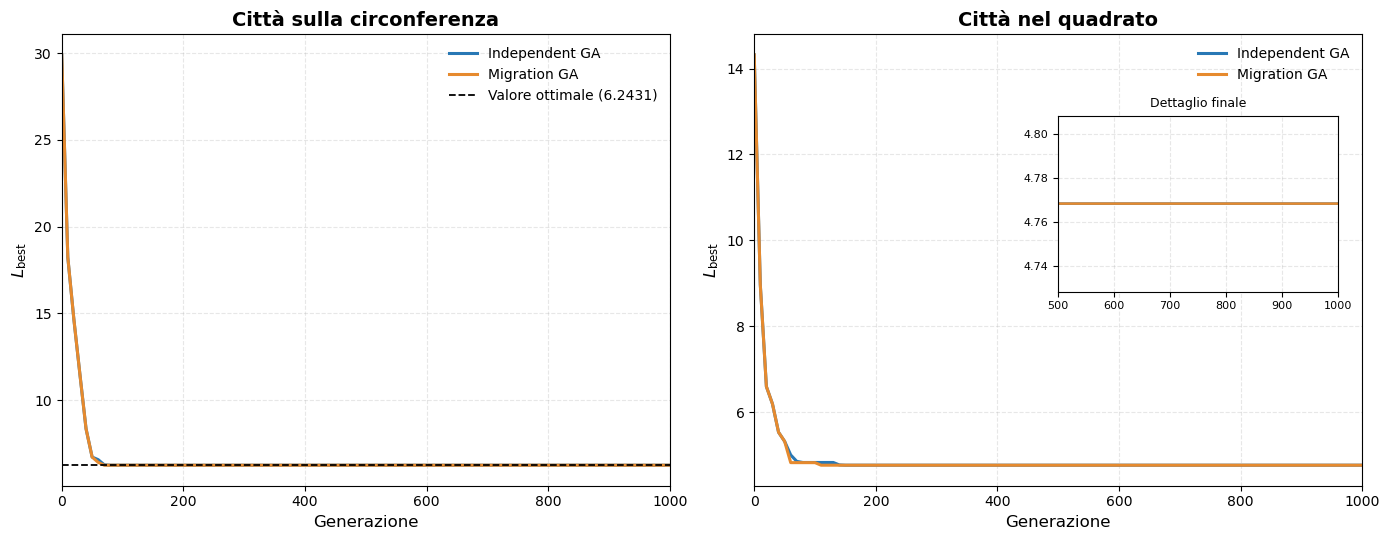

CIRCLE
  Independent GA: 6.24306
  Migration GA:   6.24306
  Miglioramento:  0.000%

SQUARE
  Independent GA: 4.76839
  Migration GA:   4.76839
  Miglioramento:  0.000%



In [13]:

# ============================================================
# Confronto della convergenza globale — Esercizio 10.1
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

colors = {
    "independent": "#2878B5",
    "migration": "#E68A2E"
}

labels = {
    "independent": "Independent GA",
    "migration": "Migration GA"
}

titles = {
    "circle": "Città sulla circonferenza",
    "square": "Città nel quadrato"
}

for ax, geometry in zip(axes, geometries):

    for mode in modes:
        df = convergence[(geometry, mode)]

        ax.plot(
            df["generation"],
            df["best_length"],
            color=colors[mode],
            linewidth=2.2,
            label=labels[mode]
        )

    # Soluzione ottimale per le città sulla circonferenza:
    # il percorso segue l'ordine angolare dei punti.
    if geometry == "circle":

        points = cities["circle"]
        angles = np.arctan2(points[:, 1], points[:, 0])
        ordered_points = points[np.argsort(angles)]

        closed_path = np.vstack([ordered_points, ordered_points[0]])

        L_opt = np.sum(
            np.linalg.norm(np.diff(closed_path, axis=0), axis=1)
        )

        ax.axhline(
            L_opt,
            color="black",
            linestyle="--",
            linewidth=1.3,
            label=f"Valore ottimale ({L_opt:.4f})"
        )

    ax.set_title(titles[geometry], fontsize=14, fontweight="bold")
    ax.set_xlabel("Generazione", fontsize=12)
    ax.set_ylabel(r"$L_{\mathrm{best}}$", fontsize=12)

    ax.set_xlim(0, N_GENERATIONS)
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(fontsize=10, frameon=False)

# ============================================================
# Ingrandimento della convergenza finale nel quadrato
# ============================================================

ax_zoom = axes[1].inset_axes([0.50, 0.43, 0.46, 0.39])

final_values = []

for mode in modes:
    df = convergence[("square", mode)]

    ax_zoom.plot(
        df["generation"],
        df["best_length"],
        color=colors[mode],
        linewidth=1.8
    )

    final_values.append(df.loc[df["generation"] >= 500, "best_length"])

zoom_values = pd.concat(final_values)

ax_zoom.set_xlim(500, N_GENERATIONS)
ax_zoom.set_ylim(zoom_values.min() - 0.04,
                 zoom_values.max() + 0.04)

ax_zoom.set_title("Dettaglio finale", fontsize=9)
ax_zoom.grid(True, linestyle="--", alpha=0.3)
ax_zoom.tick_params(labelsize=8)

plt.tight_layout()
plt.show()

# ============================================================
# Riepilogo dei risultati finali
# ============================================================

for geometry in geometries:

    L_ind = convergence[(geometry, "independent")]["best_length"].iloc[-1]
    L_mig = convergence[(geometry, "migration")]["best_length"].iloc[-1]

    improvement = 100 * (L_ind - L_mig) / L_ind

    print(f"{geometry.upper()}")
    print(f"  Independent GA: {L_ind:.5f}")
    print(f"  Migration GA:   {L_mig:.5f}")
    print(f"  Miglioramento:  {improvement:.3f}%\n")



### Analisi dei risultati

Entrambe le modalità mostrano una rapida diminuzione della lunghezza del percorso nelle prime generazioni, seguita da una fase di convergenza.

Nel caso delle **città sulla circonferenza**, sia gli algoritmi indipendenti sia quelli con migrazioni raggiungono il valore ottimale teorico $L_{\mathrm{opt}}\simeq 6.2431$.

Anche nel caso delle **città nel quadrato**, entrambe le strategie raggiungono la stessa lunghezza finale, pari a $L_{\mathrm{best}}=4.76839$.

Pertanto, nelle simulazioni con **10 processi MPI**, le migrazioni ogni 50 generazioni non producono un miglioramento della soluzione finale rispetto alle ricerche indipendenti.


La rapida convergenza osservata suggerisce che, per queste configurazioni geometriche relativamente semplici, il vantaggio delle migrazioni sia limitato.

L'efficacia dello scambio di cromosomi viene quindi approfondita nell'Esercizio 10.2, considerando un problema TSP più complesso, con 110 città italiane e differenti intervalli di migrazione.



# Esercizio 10.2 — Travelling Salesman Problem sulle città italiane

## Obiettivo e metodologia

L'algoritmo genetico parallelo sviluppato nell'Esercizio 10.1 viene applicato al **TSP delle 110 città italiane** contenute nel file `cap_prov_ita.dat`.

Le coordinate sono espresse in longitudine e latitudine. La distanza tra due città viene calcolata mediante la **formula di Haversine**, assumendo una Terra sferica di raggio $R=6371$ km:

$$
d=2R\arcsin\left[
\sqrt{
\sin^2\left(\frac{\Delta\varphi}{2}\right)
+\cos\varphi_1\cos\varphi_2
\sin^2\left(\frac{\Delta\lambda}{2}\right)
}
\right]
$$

dove $\varphi$ e $\lambda$ indicano rispettivamente latitudine e longitudine in radianti. La funzione costo restituisce quindi la lunghezza del percorso in chilometri, senza considerare la rete stradale.

## Configurazione delle simulazioni

Viene mantenuto il modello a continenti dell'esercizio precedente, utilizzando:

- **10 processi MPI**, corrispondenti a 10 popolazioni indipendenti;
- **500 individui per continente**, per un totale di 5000 individui;
- **1000 generazioni** per simulazione;
- intervalli di migrazione $N_{\mathrm{migr}}=10,20,50,100$;
- **20 trial** per ciascuna configurazione.

Vengono eseguite complessivamente **100 simulazioni**, comprendenti 20 ricerche indipendenti e 80 con migrazioni.

Le configurazioni associate allo stesso trial utilizzano le medesime condizioni iniziali, permettendo un confronto appaiato.

L'analisi considera la lunghezza finale del miglior percorso globale, la variabilità statistica tra trial, la frequenza dei miglioramenti e i tempi di esecuzione.

L'obiettivo è valutare se le migrazioni producano un vantaggio sistematico rispetto alle ricerche indipendenti e individuare l'intervallo più efficace tra quelli esaminati.


Numero di città: 110
Processi MPI: 10
Generazioni: 1000
Trial per configurazione: 20

Simulazioni caricate: 100
Confronti appaiati: 80



,L media (km),Dev. standard (km),Tempo medio (s),Vittorie (%)
configuration,,,,
Independent GA,6365.76,67.62,0.84,NaN
Migration 10,6300.03,105.67,1.00,75.0
Migration 20,6241.83,56.77,0.96,95.0
Migration 50,6226.58,102.62,0.91,95.0
Migration 100,6270.82,68.72,0.89,80.0


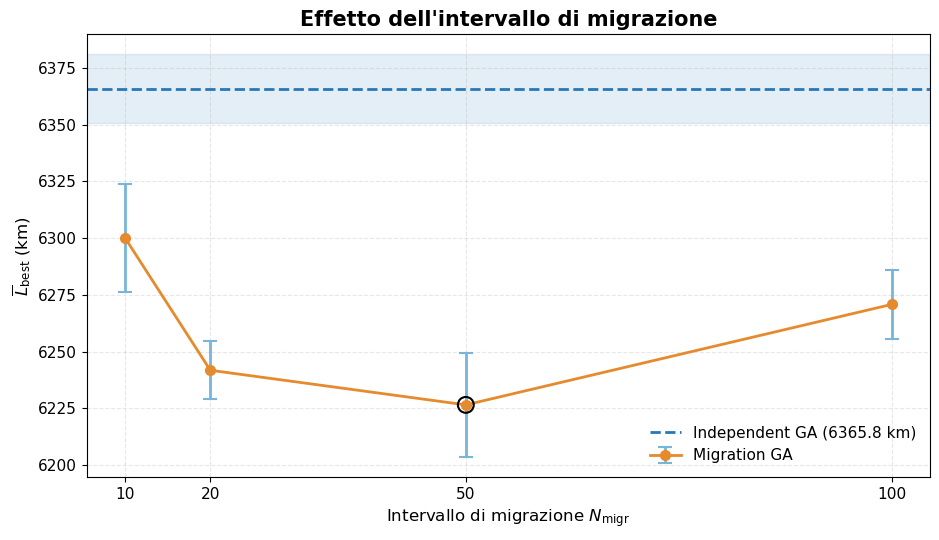

RISULTATI DEL CONFRONTO

N_migr =  10 | L_media = 6300.03 km | Miglioramento = 1.03%
N_migr =  20 | L_media = 6241.83 km | Miglioramento = 1.95%
N_migr =  50 | L_media = 6226.58 km | Miglioramento = 2.19%
N_migr = 100 | L_media = 6270.82 km | Miglioramento = 1.49%

Migliore intervallo per lunghezza media: N_migr = 50


In [20]:

# ============================================================
# Esercizio 10.2 — Importazione dei risultati
# ============================================================

N_CITIES_ITA = 110
N_RANKS_ITA = 10
N_TRIALS = 20
N_GENERATIONS_ITA = 1000

migration_intervals = [10, 20, 50, 100]

# Cartella contenente i risultati delle simulazioni MPI
DATA_DIR_ITA = Path("Esercizio_10.2/results_10_2_np10")

# ============================================================
# Caricamento dei tre file CSV
# ============================================================

summary = pd.read_csv(DATA_DIR_ITA / "summary.csv")
trials = pd.read_csv(DATA_DIR_ITA / "trial_results.csv")
paired = pd.read_csv(DATA_DIR_ITA / "paired_comparison.csv")

# ============================================================
# Preparazione delle etichette
# ============================================================

summary["configuration"] = summary.apply(
    lambda row: (
        "Independent GA"
        if row["mode"] == "independent"
        else f"Migration {int(row['interval'])}"
    ),
    axis=1
)

trials["configuration"] = trials.apply(
    lambda row: (
        "Independent GA"
        if row["mode"] == "independent"
        else f"Migration {int(row['interval'])}"
    ),
    axis=1
)

configuration_order = [
    "Independent GA",
    "Migration 10",
    "Migration 20",
    "Migration 50",
    "Migration 100"
]

# ============================================================
# Controllo dei dati
# ============================================================

print(f"Numero di città: {N_CITIES_ITA}")
print(f"Processi MPI: {N_RANKS_ITA}")
print(f"Generazioni: {N_GENERATIONS_ITA}")
print(f"Trial per configurazione: {N_TRIALS}")

print(f"\nSimulazioni caricate: {len(trials)}")
print(f"Confronti appaiati: {len(paired)}\n")

# ============================================================
# Tabella riassuntiva
# ============================================================

summary_table = summary.set_index("configuration").loc[
    configuration_order,
    [
        "mean_best_km",
        "std_best_km",
        "mean_time_s",
        "win_rate_pct"
    ]
].copy()

summary_table.columns = [
    "L media (km)",
    "Dev. standard (km)",
    "Tempo medio (s)",
    "Vittorie (%)"
]

display(summary_table.round(2))



# ============================================================
# Lunghezza media in funzione dell'intervallo di migrazione
# ============================================================

# Selezione dei risultati
independent = summary[summary["mode"] == "independent"].iloc[0]

migration = (
    summary[summary["mode"] == "migration"]
    .sort_values("interval")
    .copy()
)

# Risultati degli algoritmi indipendenti
L_ind = independent["mean_best_km"]
sem_ind = independent["std_best_km"] / np.sqrt(independent["n_trials"])

# Risultati degli algoritmi con migrazioni
intervals = migration["interval"].to_numpy(dtype=int)
L_mean = migration["mean_best_km"].to_numpy()
L_sem = (
    migration["std_best_km"] /
    np.sqrt(migration["n_trials"])
).to_numpy()

# ============================================================
# Grafico
# ============================================================

fig, ax = plt.subplots(figsize=(9.5, 5.5))

# Riferimento: algoritmi indipendenti
ax.axhline(
    L_ind,
    color="#2878B5",
    linestyle="--",
    linewidth=2,
    label=f"Independent GA ({L_ind:.1f} km)"
)

# Banda di incertezza della media indipendente
ax.axhspan(
    L_ind - sem_ind,
    L_ind + sem_ind,
    color="#2878B5",
    alpha=0.12
)

# Algoritmi con migrazioni
ax.errorbar(
    intervals,
    L_mean,
    yerr=L_sem,
    fmt="o-",
    color="#E68A2E",
    ecolor="#77B5D9",
    markersize=7,
    linewidth=2,
    elinewidth=2,
    capsize=5,
    capthick=1.5,
    label="Migration GA"
)

# Evidenziazione della configurazione con media minore
best_idx = np.argmin(L_mean)

ax.scatter(
    intervals[best_idx],
    L_mean[best_idx],
    s=130,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    zorder=5
)

# ============================================================
# Personalizzazione
# ============================================================

ax.set_title(
    "Effetto dell'intervallo di migrazione",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(r"Intervallo di migrazione $N_{\mathrm{migr}}$", fontsize=12)
ax.set_ylabel(r"$\overline{L}_{\mathrm{best}}$ (km)", fontsize=12)

ax.set_xticks(intervals)
ax.grid(True, linestyle="--", alpha=0.3)

ax.legend(fontsize=11, frameon=False)
ax.tick_params(labelsize=11)

plt.tight_layout()
plt.show()

# ============================================================
# Riepilogo numerico
# ============================================================

print("RISULTATI DEL CONFRONTO\n")

for interval, mean in zip(intervals, L_mean):

    improvement = 100 * (L_ind - mean) / L_ind

    print(
        f"N_migr = {interval:3d} | "
        f"L_media = {mean:.2f} km | "
        f"Miglioramento = {improvement:.2f}%"
    )

print(
    f"\nMigliore intervallo per lunghezza media: "
    f"N_migr = {intervals[best_idx]}"
)



### Analisi dei risultati

Il grafico mostra che tutte le configurazioni con migrazioni producono una **lunghezza media inferiore** rispetto agli algoritmi genetici indipendenti.

Il risultato migliore si ottiene per $N_{\mathrm{migr}}=50$, con una lunghezza media di $6226.58$ km, rispetto ai $6365.76$ km del caso indipendente. Si osserva quindi un **miglioramento del 2.19%**.

La configurazione con $N_{\mathrm{migr}}=20$ presenta una lunghezza media leggermente superiore ($6241.83$ km), ma anche una minore variabilità tra i trial.

L'andamento suggerisce che una frequenza intermedia delle migrazioni possa rappresentare un buon compromesso tra **esplorazione indipendente** delle popolazioni e **condivisione delle soluzioni migliori**.

Le barre d'errore rappresentano l'errore standard della media, calcolato sui 20 trial. La loro sovrapposizione per $N_{\mathrm{migr}}=20$ e $50$ non permette di stabilire quale configurazione sia statisticamente superiore.

L'analisi viene quindi approfondita attraverso lo studio delle distribuzioni delle lunghezze finali e dei confronti appaiati tra i diversi algoritmi.


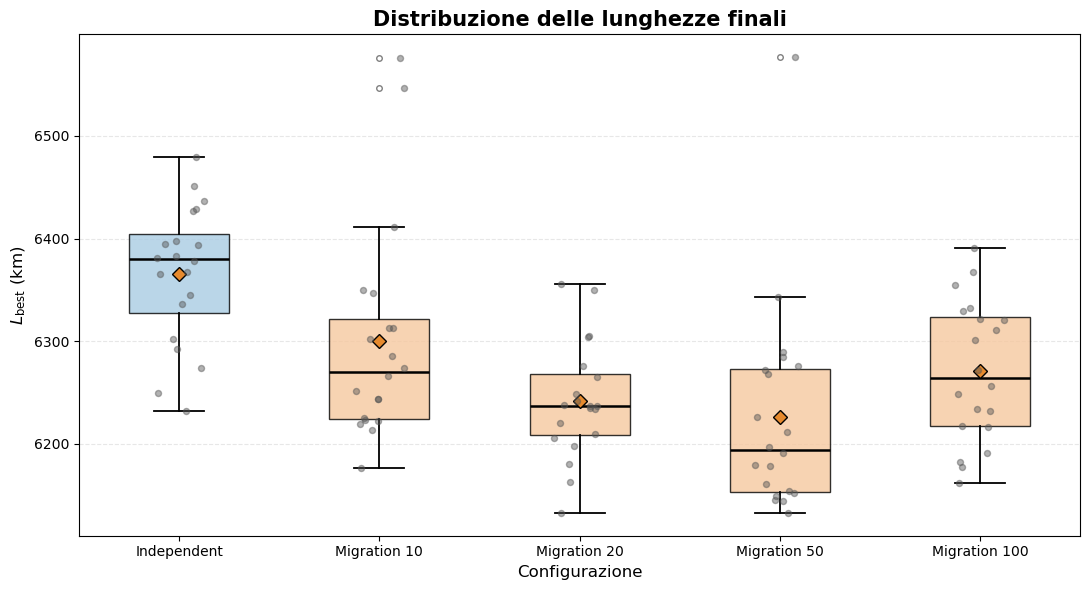

STATISTICHE DELLE LUNGHEZZE FINALI

Independent     | Media = 6365.76 km | Mediana = 6379.74 km | Dev.std = 67.62 km
Migration 10    | Media = 6300.03 km | Mediana = 6270.26 km | Dev.std = 105.67 km
Migration 20    | Media = 6241.83 km | Mediana = 6236.97 km | Dev.std = 56.77 km
Migration 50    | Media = 6226.58 km | Mediana = 6194.35 km | Dev.std = 102.62 km
Migration 100   | Media = 6270.82 km | Mediana = 6264.04 km | Dev.std = 68.72 km


In [16]:

# ============================================================
# Distribuzione delle lunghezze finali — 20 trial
# ============================================================

# Preparazione dei dati
data_boxplot = [
    trials.loc[
        trials["configuration"] == config, "best_km"
    ].dropna().to_numpy()
    for config in configuration_order
]

labels = [
    "Independent",
    "Migration 10",
    "Migration 20",
    "Migration 50",
    "Migration 100"
]

# ============================================================
# Grafico
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

bp = ax.boxplot(
    data_boxplot,
    patch_artist=True,
    widths=0.5,
    showmeans=True,
    meanprops=dict(
        marker="D",
        markerfacecolor="#E68A2E",
        markeredgecolor="black",
        markersize=7
    ),
    medianprops=dict(
        color="black",
        linewidth=1.8
    ),
    whiskerprops=dict(linewidth=1.3),
    capprops=dict(linewidth=1.3),
    flierprops=dict(
        marker="o",
        markersize=4,
        alpha=0.5
    )
)

# Colori dei boxplot
colors = ["#A9CCE3"] + ["#F6C89F"] * 4

for box, color in zip(bp["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.8)

# Singoli trial sovrapposti ai boxplot
rng = np.random.default_rng(42)

for i, values in enumerate(data_boxplot, start=1):

    x = i + rng.uniform(-0.13, 0.13, size=len(values))

    ax.scatter(
        x,
        values,
        color="#555555",
        s=19,
        alpha=0.45,
        zorder=3
    )

# ============================================================
# Personalizzazione
# ============================================================

ax.set_title(
    "Distribuzione delle lunghezze finali",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Configurazione", fontsize=12)
ax.set_ylabel(r"$L_{\mathrm{best}}$ (km)", fontsize=12)

ax.set_xticks(range(1, len(labels) + 1))
ax.set_xticklabels(labels, fontsize=10)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# ============================================================
# Riepilogo delle distribuzioni
# ============================================================

print("STATISTICHE DELLE LUNGHEZZE FINALI\n")

for label, values in zip(labels, data_boxplot):

    print(
        f"{label:15s} | "
        f"Media = {np.mean(values):.2f} km | "
        f"Mediana = {np.median(values):.2f} km | "
        f"Dev.std = {np.std(values, ddof=1):.2f} km"
    )



### Analisi delle distribuzioni

I boxplot confermano che le configurazioni con migrazioni producono generalmente percorsi più corti rispetto agli algoritmi genetici indipendenti.

La configurazione con $N_{\mathrm{migr}}=50$ presenta la **media e la mediana più basse**, rispettivamente $6226.58$ km e $6194.35$ km, ma mostra anche una dispersione relativamente elevata e alcuni valori anomali.

Con $N_{\mathrm{migr}}=20$ si osserva invece la **deviazione standard più bassa** tra tutte le configurazioni, pari a $56.77$ km, indicando risultati più stabili tra i 20 trial.

Le migrazioni migliorano quindi mediamente la qualità delle soluzioni, ma la scelta dell'intervallo influenza sia la lunghezza dei percorsi sia la variabilità dei risultati.

Per approfondire il ruolo delle migrazioni viene successivamente analizzata la convergenza dei singoli continenti, identificati dai rispettivi rank MPI.


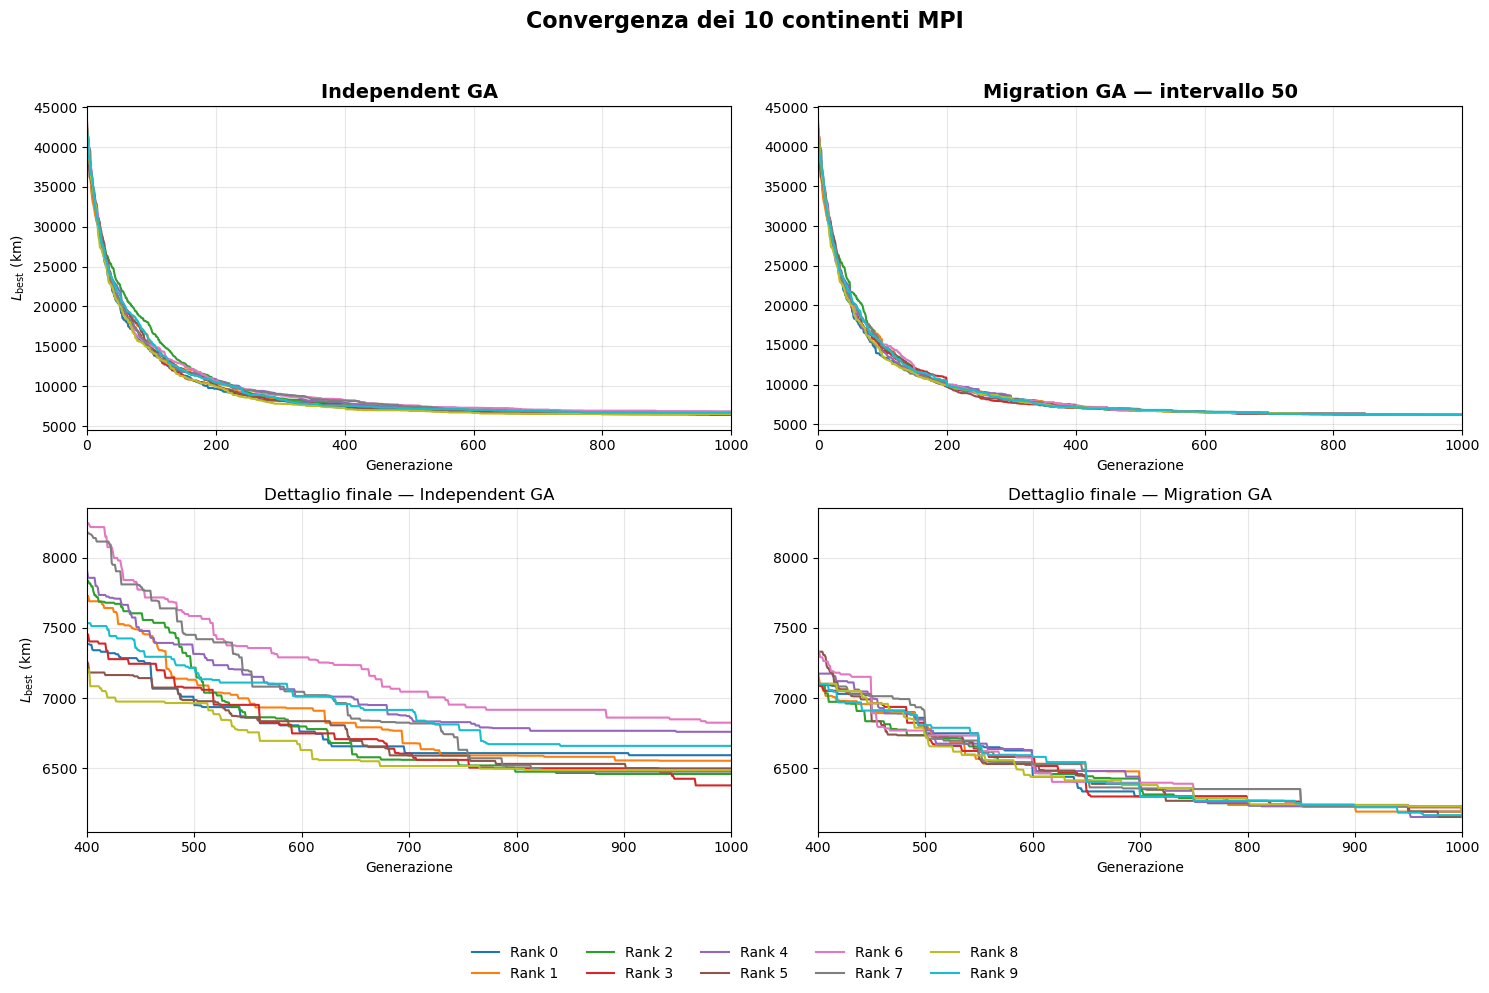

Independent GA | Rank migliore = 3 | L_best = 6378.28 km
Migration GA — intervallo 50 | Rank migliore = 4 | L_best = 6153.70 km


In [17]:

# ============================================================
# Convergenza dei 10 continenti MPI — Trial 0
# ============================================================

TRIAL_PLOT = 0
N_MIGR_PLOT = 50
ZOOM_START = 400

rank_convergence = {}

# ============================================================
# Caricamento delle convergenze dei singoli rank
# ============================================================

for mode in ["independent", "migration"]:

    folder = (
        "independent" if mode == "independent"
        else f"migration_{N_MIGR_PLOT}"
    )

    for rank in range(N_RANKS_ITA):

        filename = DATA_DIR_ITA / folder / (
            f"italy_{mode}_trial_{TRIAL_PLOT}_"
            f"rank_{rank}_convergence.txt"
        )

        rank_convergence[(mode, rank)] = pd.read_csv(
            filename,
            sep=r"\s+",
            comment="#",
            header=None,
            names=[
                "generation",
                "best_current",
                "best_ever",
                "best_half_mean"
            ]
        )

# ============================================================
# Grafici: convergenza completa e dettaglio finale
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

cmap = plt.get_cmap("tab10")

titles = {
    "independent": "Independent GA",
    "migration": f"Migration GA — intervallo {N_MIGR_PLOT}"
}

for j, mode in enumerate(["independent", "migration"]):

    ax_full = axes[0, j]
    ax_zoom = axes[1, j]

    for rank in range(N_RANKS_ITA):

        df = rank_convergence[(mode, rank)]

        # Una curva per ciascun continente
        ax_full.plot(
            df["generation"],
            df["best_ever"],
            color=cmap(rank),
            linewidth=1.5,
            label=f"Rank {rank}"
        )

        ax_zoom.plot(
            df["generation"],
            df["best_ever"],
            color=cmap(rank),
            linewidth=1.5
        )

    ax_full.set_title(
        titles[mode], fontsize=14, fontweight="bold"
    )

    ax_full.set_xlim(0, N_GENERATIONS_ITA)
    ax_zoom.set_xlim(ZOOM_START, N_GENERATIONS_ITA)

    ax_full.set_xlabel("Generazione")
    ax_zoom.set_xlabel("Generazione")

    ax_full.grid(True, alpha=0.3)
    ax_zoom.grid(True, alpha=0.3)

# Stessa scala verticale nei due pannelli di dettaglio
zoom_values = np.concatenate([
    df.loc[df["generation"] >= ZOOM_START, "best_ever"].to_numpy()
    for df in rank_convergence.values()
])

margin = 0.05 * (zoom_values.max() - zoom_values.min())

for ax in axes[1, :]:
    ax.set_ylim(
        zoom_values.min() - margin,
        zoom_values.max() + margin
    )

axes[0, 0].set_ylabel(r"$L_{\mathrm{best}}$ (km)")
axes[1, 0].set_ylabel(r"$L_{\mathrm{best}}$ (km)")

axes[1, 0].set_title("Dettaglio finale — Independent GA")
axes[1, 1].set_title("Dettaglio finale — Migration GA")

# Legenda comune dei 10 rank
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    fontsize=10
)

fig.suptitle(
    "Convergenza dei 10 continenti MPI",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.96])
plt.show()

# ============================================================
# Miglior risultato globale del trial selezionato
# ============================================================

for mode in ["independent", "migration"]:

    final_lengths = np.array([
        rank_convergence[(mode, rank)]["best_ever"].iloc[-1]
        for rank in range(N_RANKS_ITA)
    ])

    best_rank = np.argmin(final_lengths)

    print(
        f"{titles[mode]} | "
        f"Rank migliore = {best_rank} | "
        f"L_best = {final_lengths[best_rank]:.2f} km"
    )



### Convergenza dei singoli continenti

Le curve mostrano l'evoluzione del miglior percorso trovato da ciascun continente, identificato dal proprio rank MPI.

Nella fase iniziale tutte le popolazioni presentano una rapida diminuzione della funzione costo, seguita da un rallentamento progressivo della convergenza.

Nel caso **independent**, i continenti mantengono traiettorie distinte anche nelle ultime generazioni. Le lunghezze finali risultano distribuite su un intervallo relativamente ampio, segnalando una maggiore eterogeneità tra le popolazioni.

Nel caso **migration** con $N_{\mathrm{migr}}=50$, le curve tendono invece ad avvicinarsi maggiormente nella parte finale della simulazione. Questo comportamento è coerente con il meccanismo di migrazione, che favorisce la diffusione dei cromosomi migliori tra i continenti.

Si osserva inoltre che la configurazione con migrazioni raggiunge valori finali mediamente più bassi rispetto al caso indipendente. Le migrazioni sembrano quindi migliorare non soltanto la qualità media della soluzione finale, ma anche la capacità dei continenti di convergere verso risultati simili e più favorevoli.

L'analisi dei singoli rank conferma quindi che lo scambio periodico di informazione genetica modifica in modo visibile la dinamica evolutiva del sistema parallelo.

MIGLIOR RISULTATO ASSOLUTO

Modalità:          Migration GA — N_migr = 20
Trial:             9
L_best:            6132.66 km
Lunghezza ricalc.: 6132.66 km
Città visitate:    110
Città iniziale:    Agrigento


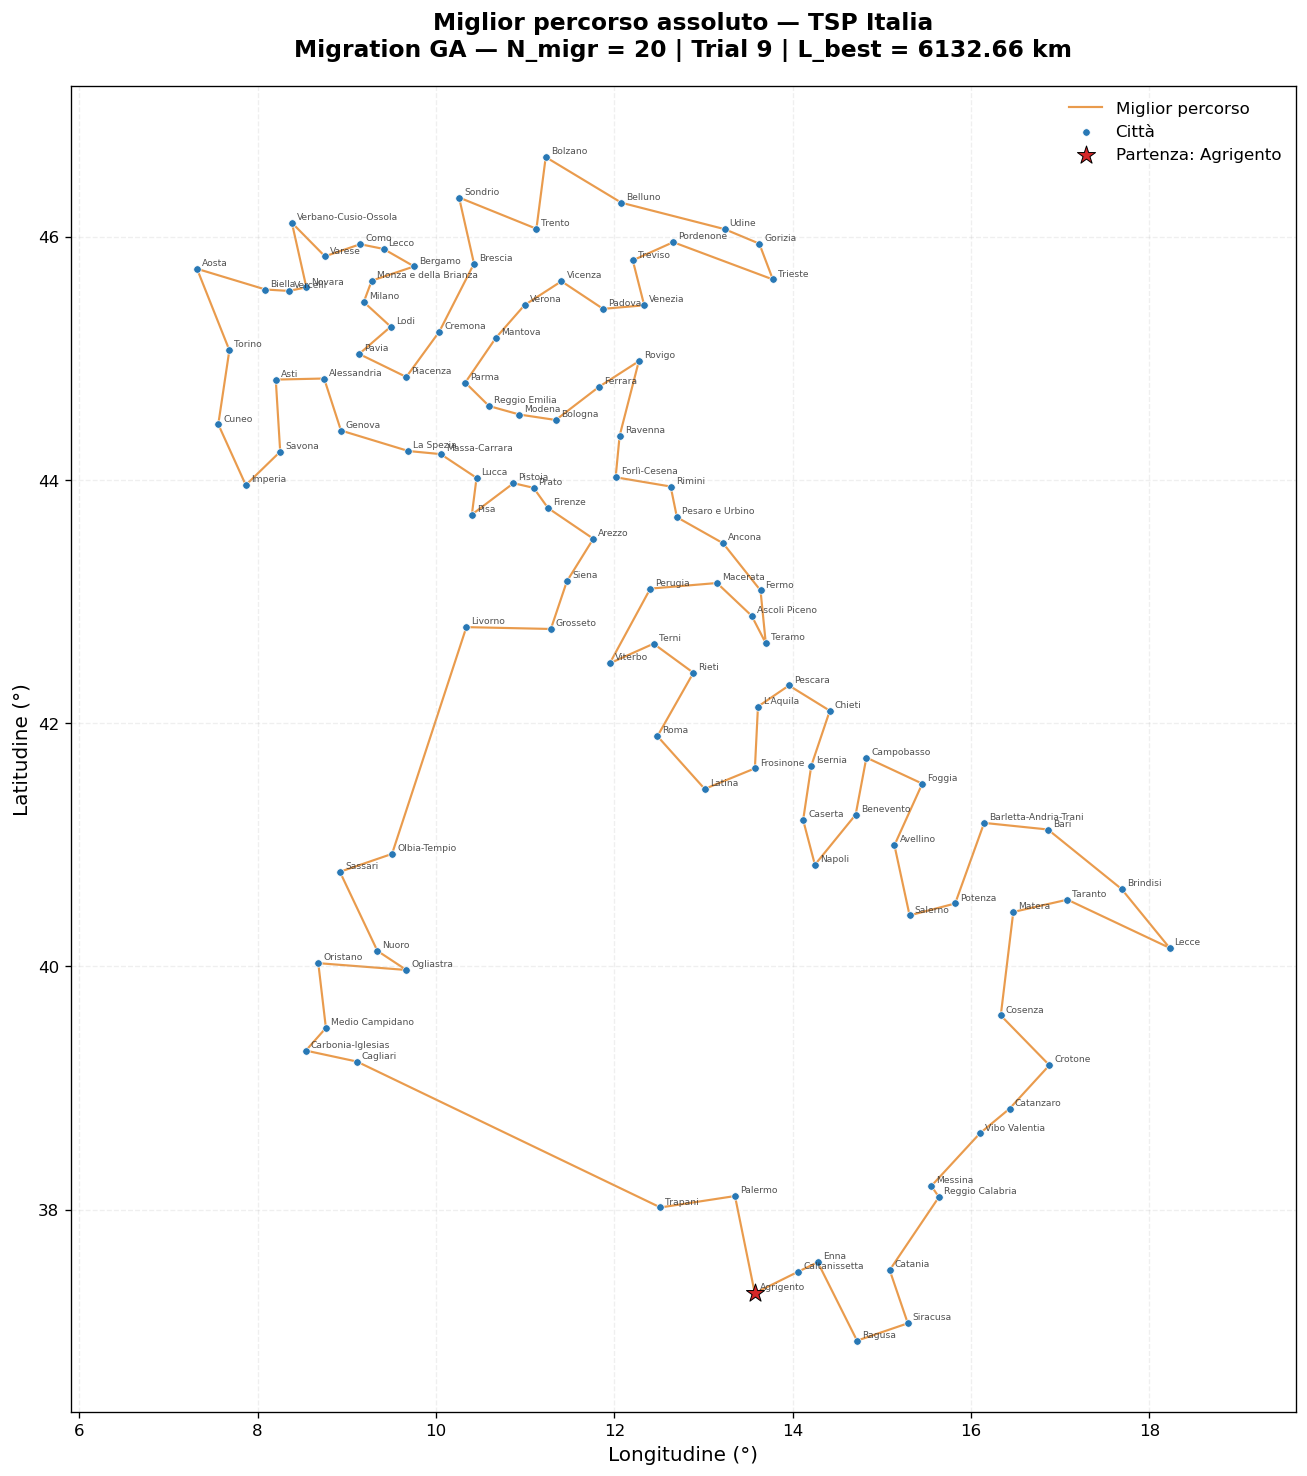

In [19]:

# ============================================================
# Miglior percorso assoluto — TSP delle 110 città italiane
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT_DIR = Path("Esercizio_10.2")
DATA_DIR_ITA = ROOT_DIR / "results_10_2_np10"

# ============================================================
# Caricamento delle coordinate e dei nomi
# ============================================================

city_file = ROOT_DIR / "cap_prov_ita.dat"
names_file = ROOT_DIR / "prov_ita.txt"

# Coordinate geografiche: longitudine, latitudine
coordinates = np.loadtxt(city_file)

lon = coordinates[:, 0]
lat = coordinates[:, 1]

# I nomi sono nello stesso ordine delle coordinate
with open(names_file, "r", encoding="utf-8-sig") as f:
    city_names = [line.strip() for line in f if line.strip()]

N_CITIES = len(coordinates)

if len(city_names) != N_CITIES:
    raise ValueError(
        "Il numero dei nomi non coincide con quello delle coordinate."
    )

# ============================================================
# Ricerca del miglior percorso fra tutti i trial
# ============================================================

best_row = trials.loc[trials["best_km"].idxmin()]

best_mode = best_row["mode"]
best_trial = int(best_row["trial"])
best_length = float(best_row["best_km"])

if best_mode == "independent":

    folder = DATA_DIR_ITA / "independent"

    filename = (
        f"italy_independent_trial_{best_trial}_"
        f"global_best_path.txt"
    )

    mode_label = "Independent GA"

else:

    best_interval = int(best_row["interval"])

    folder = DATA_DIR_ITA / f"migration_{best_interval}"

    filename = (
        f"italy_migration_trial_{best_trial}_"
        f"global_best_path.txt"
    )

    mode_label = f"Migration GA — N_migr = {best_interval}"

path_file = folder / filename

# ============================================================
# Lettura del percorso
# ============================================================

# Formato del file:
# colonna 0 -> ordine di visita
# colonna 1 -> indice della città (1, ..., 110)
# colonna 2 -> longitudine
# colonna 3 -> latitudine

path_data = np.loadtxt(path_file, comments="#", ndmin=2)

city_indices = path_data[:, 1].astype(int)

# Il file contiene 111 righe:
# l'ultima ripete la città iniziale per chiudere il percorso.
if (
    len(city_indices) == N_CITIES + 1
    and city_indices[-1] == city_indices[0]
):
    city_indices = city_indices[:-1]

# Conversione dagli indici C++ (1,...,110)
# agli indici Python (0,...,109)
best_path = city_indices - 1

# Verifica della permutazione
if not np.array_equal(np.sort(best_path), np.arange(N_CITIES)):
    raise ValueError("Il percorso non contiene tutte le città una sola volta.")

# Chiusura del percorso per il grafico
closed_path = np.append(best_path, best_path[0])

# ============================================================
# Verifica della lunghezza tramite formula di Haversine
# ============================================================

lon_path = np.radians(lon[closed_path])
lat_path = np.radians(lat[closed_path])

delta_lon = np.diff(lon_path)
delta_lat = np.diff(lat_path)

a = (
    np.sin(delta_lat / 2)**2
    + np.cos(lat_path[:-1])
    * np.cos(lat_path[1:])
    * np.sin(delta_lon / 2)**2
)

L_check = np.sum(
    2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

print("MIGLIOR RISULTATO ASSOLUTO\n")
print(f"Modalità:          {mode_label}")
print(f"Trial:             {best_trial}")
print(f"L_best:            {best_length:.2f} km")
print(f"Lunghezza ricalc.: {L_check:.2f} km")
print(f"Città visitate:    {len(best_path)}")
print(f"Città iniziale:    {city_names[best_path[0]]}")

# ============================================================
# Rappresentazione geografica del percorso
# ============================================================

fig, ax = plt.subplots(figsize=(11, 13), dpi=120)

# Percorso migliore
ax.plot(
    lon[closed_path],
    lat[closed_path],
    color="#E68A2E",
    linewidth=1.3,
    alpha=0.85,
    zorder=1,
    label="Miglior percorso"
)

# Posizione delle città
ax.scatter(
    lon,
    lat,
    s=20,
    color="#2878B5",
    edgecolors="white",
    linewidths=0.4,
    zorder=3,
    label="Città"
)

# Etichette piccole delle province
for i, name in enumerate(city_names):

    ax.annotate(
        name,
        xy=(lon[i], lat[i]),
        xytext=(3, 2),
        textcoords="offset points",
        fontsize=5.5,
        color="#333333",
        alpha=0.85,
        zorder=4
    )

# Evidenziazione della città iniziale
start = best_path[0]

ax.scatter(
    lon[start],
    lat[start],
    s=130,
    marker="*",
    color="#D62728",
    edgecolors="black",
    linewidths=0.6,
    zorder=5,
    label=f"Partenza: {city_names[start]}"
)

# ============================================================
# Personalizzazione del grafico
# ============================================================

ax.set_title(
    "Miglior percorso assoluto — TSP Italia\n"
    f"{mode_label} | Trial {best_trial} | "
    f"L_best = {best_length:.2f} km",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Longitudine (°)", fontsize=12)
ax.set_ylabel("Latitudine (°)", fontsize=12)

# Correzione approssimata delle proporzioni geografiche
ax.set_aspect(
    1 / np.cos(np.radians(np.mean(lat)))
)

ax.margins(x=0.13, y=0.06)
ax.grid(True, linestyle="--", alpha=0.2)
ax.legend(loc="upper right", frameon=False, fontsize=10)

plt.tight_layout()
plt.show()



### Analisi del miglior percorso

La rappresentazione geografica mostra il **miglior percorso individuato nelle 100 simulazioni**, ottenuto con 10 processi MPI, intervallo di migrazione $N_{\mathrm{migr}}=20$ e trial 9.

La lunghezza complessiva risulta:

$$
L_{\mathrm{best}}=6132.66\ \mathrm{km}
$$

Esso è stato ottenuto nel **trial 9**, dal continente identificato dal **rank MPI 0**

La lunghezza minima individuata risulta pari a $L_{\mathrm{best}}=6132.66$ km.

Il percorso attraversa tutte le 110 città esattamente una volta, ritornando infine alla città iniziale, Agrigento. I collegamenti rappresentano le distanze geografiche minime sulla superficie terrestre sferica, senza considerare la rete stradale.

Si osserva una tendenza a collegare città geograficamente vicine, limitando gli spostamenti più lunghi, in particolare tra le diverse aree della penisola e le isole.

È interessante osservare che il **miglior singolo percorso** è stato ottenuto con $N_{\mathrm{migr}}=20$, mentre la configurazione con $N_{\mathrm{migr}}=50$ ha prodotto la lunghezza media più bassa sui 20 trial.

Questo evidenzia la distinzione tra la migliore soluzione individuale e le prestazioni medie di un algoritmo stocastico. Il percorso rappresentato costituisce la migliore soluzione trovata sperimentalmente, senza garantire il raggiungimento dell'ottimo globale.
